# Brief Seattle — Analyse exploratoire

Chargement des relevés 2016 (*Building Energy Benchmarking*) de la ville de Seattle.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)  # afficher toutes les colonnes (46)

RANDOM_STATE = 42  # graine fixée pour la reproductibilité

## Chargement des données

In [2]:
# Chemin relatif au dossier notebooks/
DATA_PATH = Path("..") / "data" / "raw" / "2016_Building_Energy_Benchmarking.csv"

df = pd.read_csv(DATA_PATH)
print(f"{df.shape[0]} lignes x {df.shape[1]} colonnes")

3376 lignes x 46 colonnes


In [3]:
df.head()

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12,88434,0,88434,Hotel,Hotel,88434.0,NaN,NaN,NaN,NaN,NaN,60.0,81.699997,84.300003,182.500000,189.000000,7226362.5,7456910.0,2003882.00,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11,103566,15064,88502,"Hotel, Parking, Restaurant",Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,NaN,61.0,94.800003,97.900002,176.100006,179.399994,8387933.0,8664479.0,0.00,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,7,DOWNTOWN,47.61393,-122.33810,1969,1.0,41,956110,196718,759392,Hotel,Hotel,756493.0,NaN,NaN,NaN,NaN,NaN,43.0,96.000000,97.699997,241.899994,244.100006,72587024.0,73937112.0,21566554.00,1.451544e+07,49526664.0,14938.00000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,7,DOWNTOWN,47.61412,-122.33664,1926,1.0,10,61320,0,61320,Hotel,Hotel,61320.0,NaN,NaN,NaN,NaN,NaN,56.0,110.800003,113.300003,216.199997,224.000000,6794584.0,6946800.5,2214446.25,8.115253e+05,2768924.0,18112.13086,1811213.0,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,7,DOWNTOWN,47.61375,-122.34047,1980,1.0,18,175580,62000,113580,"Hotel, Parking, Swimming Pool",Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,NaN,75.0,114.800003,118.699997,211.399994,215.600006,14172606.0,14656503.0,0.00,1.573449e+06,5368607.0,88039.98438,8803998.0,False,NaN,Compliant,NaN,505.01,2.88


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3376 entries, 0 to 3375
Data columns (total 46 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   OSEBuildingID                    3376 non-null   int64  
 1   DataYear                         3376 non-null   int64  
 2   BuildingType                     3376 non-null   str    
 3   PrimaryPropertyType              3376 non-null   str    
 4   PropertyName                     3376 non-null   str    
 5   Address                          3376 non-null   str    
 6   City                             3376 non-null   str    
 7   State                            3376 non-null   str    
 8   ZipCode                          3360 non-null   float64
 9   TaxParcelIdentificationNumber    3376 non-null   str    
 10  CouncilDistrictCode              3376 non-null   int64  
 11  Neighborhood                     3376 non-null   str    
 12  Latitude                       

In [5]:
df.isna().sum()

OSEBuildingID                         0
DataYear                              0
BuildingType                          0
PrimaryPropertyType                   0
PropertyName                          0
Address                               0
City                                  0
State                                 0
ZipCode                              16
TaxParcelIdentificationNumber         0
CouncilDistrictCode                   0
Neighborhood                          0
Latitude                              0
Longitude                             0
YearBuilt                             0
NumberofBuildings                     8
NumberofFloors                        0
PropertyGFATotal                      0
PropertyGFAParking                    0
PropertyGFABuilding(s)                0
ListOfAllPropertyUseTypes             9
LargestPropertyUseType               20
LargestPropertyUseTypeGFA            20
SecondLargestPropertyUseType       1697
SecondLargestPropertyUseTypeGFA    1697


In [6]:
#compte des bâtiments par type d'usage

df["BuildingType"].value_counts()


BuildingType
NonResidential          1460
Multifamily LR (1-4)    1018
Multifamily MR (5-9)     580
Multifamily HR (10+)     110
SPS-District K-12         98
Nonresidential COS        85
Campus                    24
Nonresidential WA          1
Name: count, dtype: int64

In [7]:
# Le brief cible les bâtiments non destinés à l'habitation :
# on exclut les logements collectifs (Multifamily LR / MR / HR)
df = df[~df["BuildingType"].str.startswith("Multifamily")]
print(df.shape)


(1668, 46)


In [8]:
df["PrimaryPropertyType"].value_counts()

PrimaryPropertyType
Small- and Mid-Sized Office    292
Other                          250
Warehouse                      187
Large Office                   173
K-12 School                    139
Mixed Use Property             114
Retail Store                    91
Hotel                           76
Worship Facility                71
Distribution Center             53
Supermarket / Grocery Store     40
Medical Office                  39
Self-Storage Facility           28
University                      24
Residence Hall                  21
Senior Care Community           20
Refrigerated Warehouse          12
Restaurant                      12
Hospital                        10
Laboratory                      10
Low-Rise Multifamily             3
Office                           3
Name: count, dtype: int64

In [9]:
df = df[df["PrimaryPropertyType"] != "Low-Rise Multifamily"]


In [10]:
df["ComplianceStatus"].value_counts()

ComplianceStatus
Compliant                       1546
Error - Correct Default Data      88
Non-Compliant                     17
Missing Data                      14
Name: count, dtype: int64

In [11]:
df["Outlier"].value_counts(dropna=False)

Outlier
NaN             1649
Low outlier       14
High outlier       2
Name: count, dtype: int64

In [12]:
# On retire les relevés invalidés par la ville :
# - "Missing Data" : consommation à 0, pas de vrai relevé
# - "Non-Compliant" : données non validées (contient 16 des 18 outliers)
# - Outlier : valeurs signalées comme anormales par la ville
# On garde "Error - Correct Default Data" : consommations plausibles,
# l'erreur porte sur la déclaration, pas sur la mesure.
df = df[~df["ComplianceStatus"].isin(["Missing Data", "Non-Compliant"])]
df = df[df["Outlier"].isna()]
print(df.shape)

(1632, 46)


In [13]:
cibles = ["SiteEnergyUse(kBtu)", "TotalGHGEmissions"]
df[(df[cibles] <= 0).any(axis=1)][["PropertyName"] + cibles + ["Electricity(kBtu)", "NaturalGas(kBtu)"]]


,PropertyName,SiteEnergyUse(kBtu),TotalGHGEmissions,Electricity(kBtu),NaturalGas(kBtu)
513,IUC- Whole Foods Interbay,1.252517e+07,0.0,0.0,0.0
1361,Olympic Hills Elementary,0.000000e+00,0.0,0.0,0.0
3206,Bullitt Center,3.427261e+05,-0.8,-115417.0,0.0


In [14]:
# 3 lignes avec des cibles nulles ou négatives :
# - Olympic Hills Elementary : relevé vide (tout à 0)
# - Whole Foods Interbay : énergie > 0 mais émissions/électricité/gaz à 0, incohérent
# - Bullitt Center : bâtiment à énergie positive (panneaux solaires), émissions
#   négatives réelles mais cas isolé et non modélisable
df = df[(df[cibles] > 0).all(axis=1)]
print(df.shape)  # 1629 lignes


(1629, 46)


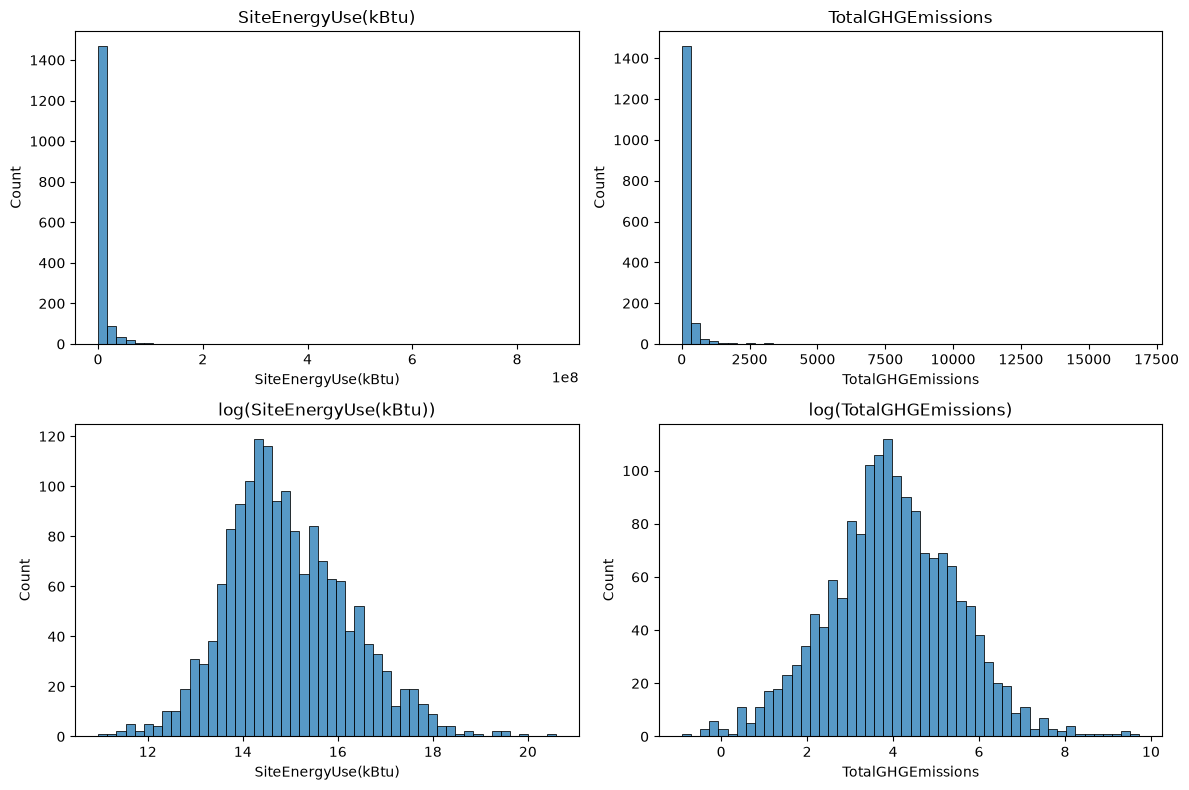

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for i, col in enumerate(cibles):
    sns.histplot(df[col], ax=axes[0, i], bins=50).set_title(col)
    sns.histplot(np.log(df[col]), ax=axes[1, i], bins=50).set_title(f"log({col})")
plt.tight_layout()


In [16]:
na = df.isna().sum()
na = na[na > 0].sort_values(ascending=False)
pd.DataFrame({"nb": na, "%": (na / len(df) * 100).round(1)})



,nb,%
Comments,1629,100.0
Outlier,1629,100.0
YearsENERGYSTARCertified,1532,94.0
ThirdLargestPropertyUseType,1280,78.6
ThirdLargestPropertyUseTypeGFA,1280,78.6
SecondLargestPropertyUseTypeGFA,784,48.1
SecondLargestPropertyUseType,784,48.1
ENERGYSTARScore,550,33.8
ZipCode,16,1.0
LargestPropertyUseType,4,0.2


In [17]:
(df["SecondLargestPropertyUseType"].isna() == df["SecondLargestPropertyUseTypeGFA"].isna()).all()  # True



np.True_

In [18]:
# Absence de 2e/3e usage = le bâtiment n'en a pas → on remplit explicitement
for rang in ["Second", "Third"]:
    df[f"{rang}LargestPropertyUseType"] = df[f"{rang}LargestPropertyUseType"].fillna("None")
    df[f"{rang}LargestPropertyUseTypeGFA"] = df[f"{rang}LargestPropertyUseTypeGFA"].fillna(0)

# 4 bâtiments sans usage principal : on reprend le type principal et la surface bâtie
df["LargestPropertyUseType"] = df["LargestPropertyUseType"].fillna(df["PrimaryPropertyType"])
df["LargestPropertyUseTypeGFA"] = df["LargestPropertyUseTypeGFA"].fillna(df["PropertyGFABuilding(s)"])


In [19]:
df.groupby(df["ENERGYSTARScore"].isna())["PrimaryPropertyType"].value_counts().unstack(0)


ENERGYSTARScore,False,True
PrimaryPropertyType,,
Distribution Center,40.0,13.0
Hospital,10.0,NaN
Hotel,72.0,3.0
K-12 School,122.0,1.0
Laboratory,NaN,10.0
Large Office,161.0,9.0
Medical Office,37.0,2.0
Mixed Use Property,26.0,87.0
Office,3.0,NaN


### Cas particulier : `ENERGYSTARScore` (34 % de valeurs manquantes)

Le tableau ci-dessus montre que les valeurs manquantes ne sont **pas réparties au hasard** : elles dépendent du type de bâtiment.
- Certains types n'ont **jamais** de score : `University`, `Restaurant`, `Laboratory`, `Self-Storage Facility`.
- D'autres en ont presque toujours : `Small- and Mid-Sized Office`, `Warehouse`, `Retail Store`.

L'ENERGY STAR Score n'est en effet calculable que pour certaines catégories de bâtiments. Une valeur manquante signifie donc le plus souvent que le bâtiment **n'est pas éligible**, et non que la mesure a été oubliée.

**Conséquence : on n'impute pas cette colonne.** La remplacer par la médiane ou la moyenne inventerait un score pour des bâtiments qui ne peuvent pas en avoir, et fausserait l'évaluation de son intérêt.

**Décision :** on conserve la colonne telle quelle (avec ses NaN) pour la phase de modélisation, où l'on comparera :
- **Modèle A, sans le score**, entraîné sur l'ensemble des bâtiments ;
- **Modèle B, avec le score**, entraîné sur les bâtiments qui en disposent.

Pour que la comparaison soit équitable, les deux modèles seront évalués **sur le même sous-ensemble de bâtiments** (ceux qui ont un score). L'écart de performance mesurera l'apport réel de l'ENERGY STAR Score à la prédiction des émissions de CO2.

In [20]:
cols_physiques = ["PropertyGFATotal", "PropertyGFAParking", "PropertyGFABuilding(s)",
                  "NumberofBuildings", "NumberofFloors", "YearBuilt"]
df[cols_physiques].describe()


,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),NumberofBuildings,NumberofFloors,YearBuilt
count,1.629000e+03,1629.000000,1.629000e+03,1629.000000,1629.000000,1629.000000
mean,1.193451e+05,13142.612646,1.062025e+05,1.170043,4.158993,1961.994475
std,2.990367e+05,42722.769523,2.856594e+05,2.962905,6.632500,32.685578
min,1.128500e+04,0.000000,3.636000e+03,0.000000,0.000000,1900.000000
25%,2.939400e+04,0.000000,2.836800e+04,1.000000,1.000000,1930.000000
50%,4.924300e+04,0.000000,4.721500e+04,1.000000,2.000000,1966.000000
75%,1.060410e+05,0.000000,9.542600e+04,1.000000,4.000000,1989.000000
max,9.320156e+06,512608.000000,9.320156e+06,111.000000,99.000000,2015.000000


In [21]:
# Campus UW : 111 bâtiments agrégés en une ligne, 19x plus grand que le 2e
# → pas un bâtiment individuel, valeur extrême isolée
df = df[df["PropertyName"] != "University of Washington - Seattle Campus"]


In [22]:
ecart = df["PropertyGFATotal"] - df["PropertyGFAParking"] - df["PropertyGFABuilding(s)"]
(ecart.abs() > 1).sum()  # 0


np.int64(0)

In [23]:
# 52 propriétés avec 0 bâtiment alors qu'elles ont une surface bâtie → erreur de saisie
df.loc[df["NumberofBuildings"] == 0, "NumberofBuildings"] = 1


In [24]:
df[df["NumberofFloors"] == 0][["PropertyName", "PrimaryPropertyType"]]

,PropertyName,PrimaryPropertyType
166,Grand Hyatt Seattle,Hotel
487,Arnold Pavilion,Medical Office
488,2200 Westlake - SEDO,Mixed Use Property
564,Pacific Place,Other
1754,HART First Hill LLC,Medical Office
1993,(ID#24086)Campus1:KC Metro Transit Atlantic Ce...,Other
3130,Sandpoint #5,Warehouse
3131,Sandpoint #25,Medical Office
3132,Sandpoint #29,Small- and Mid-Sized Office
3168,Magnuson,Other


In [25]:
df.nlargest(5, "NumberofFloors")[["PropertyName", "PrimaryPropertyType", "NumberofFloors"]]


,PropertyName,PrimaryPropertyType,NumberofFloors
1359,Seattle Chinese Baptist Church,Worship Facility,99
559,Columbia Center - 2015,Large Office,76
233,Seattle Municipal Tower (2030),Large Office,63
292,Two Union Square,Large Office,56
271,1201 Third Avenue,Large Office,55


In [26]:
# 0 étage (16 bâtiments) et 99 étages pour une église → valeurs impossibles,
# remplacées par la médiane du même PrimaryPropertyType
etages_impossibles = (df["NumberofFloors"] == 0) | (df["NumberofFloors"] == 99)
df.loc[etages_impossibles, "NumberofFloors"] = np.nan
df["NumberofFloors"] = df["NumberofFloors"].fillna(
    df.groupby("PrimaryPropertyType")["NumberofFloors"].transform("median")
)


In [27]:
print(df.nunique().sort_values().to_string())   # force l'affichage de toutes les lignes
       # trié : les colonnes à 0-1 valeur en haut



Comments                              0
Outlier                               0
DataYear                              1
State                                 1
City                                  1
ComplianceStatus                      2
DefaultData                           2
BuildingType                          5
CouncilDistrictCode                   7
NumberofBuildings                    14
Neighborhood                         19
PrimaryPropertyType                  21
ThirdLargestPropertyUseType          40
NumberofFloors                       43
ZipCode                              48
SecondLargestPropertyUseType         48
LargestPropertyUseType               56
YearsENERGYSTARCertified             64
ENERGYSTARScore                     100
YearBuilt                           113
SteamUse(kBtu)                      114
ThirdLargestPropertyUseTypeGFA      299
PropertyGFAParking                  324
ListOfAllPropertyUseTypes           367
GHGEmissionsIntensity               460


In [28]:
somme = df["Electricity(kBtu)"] + df["NaturalGas(kBtu)"] + df["SteamUse(kBtu)"]
(somme / df["SiteEnergyUse(kBtu)"]).describe()   # ≈ 1 partout


count    1628.000000
mean        0.997935
std         0.034021
min         0.209771
25%         1.000000
50%         1.000000
75%         1.000000
max         1.237346
dtype: float64

In [29]:
# 2 bâtiments dont électricité + gaz + vapeur dépasse la consommation totale
# (ratio > 1) : physiquement impossible → relevé incohérent, on les retire
somme = df["Electricity(kBtu)"] + df["NaturalGas(kBtu)"] + df["SteamUse(kBtu)"]
ratio = somme / df["SiteEnergyUse(kBtu)"]

print(df.loc[ratio > 1.05, "PropertyName"])  # affiche les 2 bâtiments concernés
df = df[ratio <= 1.05]
print(df.shape)  # 1626 lignes


563     Market Place I & II-2003 Western Avenue
2441                         Buttnick City Loan
Name: PropertyName, dtype: str
(1626, 46)


In [30]:
# Info de raccordement (connue sans relevé) : le bâtiment utilise-t-il du gaz / de la vapeur ?
df["UsesNaturalGas"] = (df["NaturalGas(kBtu)"] > 0).astype(int)
df["UsesSteam"] = (df["SteamUse(kBtu)"] > 0).astype(int)


In [31]:
# Plant 2 Site : campus déclaré comme bureaux (3 étages), mais 1er consommateur et
# 1er émetteur du jeu de données, avec une intensité 14x supérieure à la médiane de
# son type (consommation de gaz typique d'une activité industrielle).
# Activité non décrite par nos variables → non prédictible, retiré.
df = df[df["PropertyName"] != "Plant 2 Site"]

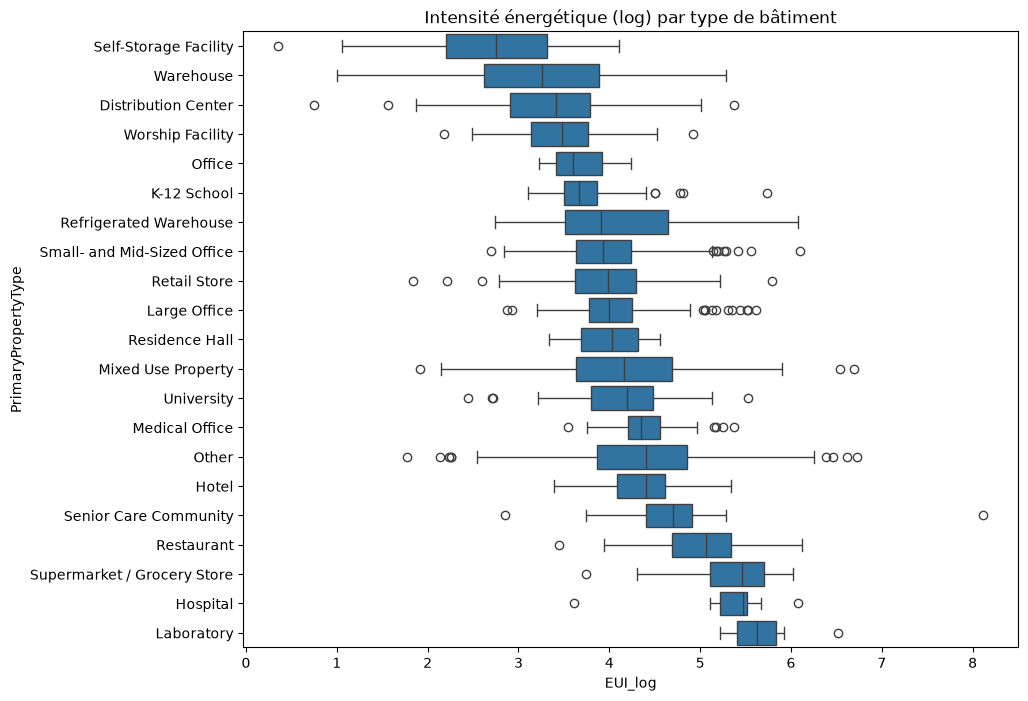

In [32]:
# Intensité énergétique (kBtu / pied²) : neutralise l'effet taille.
# Colonne temporaire pour l'analyse des outliers uniquement, à ne PAS garder comme variable
# (elle est calculée à partir de la cible → fuite de données)
df["EUI_log"] = np.log(df["SiteEnergyUse(kBtu)"] / df["PropertyGFABuilding(s)"])

ordre = df.groupby("PrimaryPropertyType")["EUI_log"].median().sort_values().index
plt.figure(figsize=(10, 8))
sns.boxplot(data=df, y="PrimaryPropertyType", x="EUI_log", order=ordre)
plt.title("Intensité énergétique (log) par type de bâtiment")
plt.show()


In [33]:
q1 = df.groupby("PrimaryPropertyType")["EUI_log"].transform(lambda x: x.quantile(0.25))
q3 = df.groupby("PrimaryPropertyType")["EUI_log"].transform(lambda x: x.quantile(0.75))
iqr = q3 - q1
extremes = (df["EUI_log"] < q1 - 3 * iqr) | (df["EUI_log"] > q3 + 3 * iqr)
df.loc[extremes, ["PropertyName", "PrimaryPropertyType", "EUI_log"]]


,PropertyName,PrimaryPropertyType,EUI_log
601,200 SW Michigan,Small- and Mid-Sized Office,6.099937
888,Cabrini Senior Housing,Senior Care Community,2.849180
954,University Prep Academy,K-12 School,5.740194
1109,Ballard Center,Senior Care Community,8.114095
2482,Park West Skilled Nursing,Hospital,3.614748


In [34]:
# Outliers extrêmes d'intensité énergétique (règle 3×IQR par type), examinés un par un :
# - Ballard Center, University Prep Academy : surface bâtie incohérente avec la surface
#   de l'usage principal (erreur de saisie) → retirés
# - Park West Skilled Nursing : classé Hospital (maison de soins), surface d'usage = 2x
#   la surface totale → retiré
# - Cabrini Senior Housing, 200 SW Michigan : surfaces cohérentes, valeurs extrêmes
#   confirmées par l'ENERGY STAR Score (100 et 1) → bâtiments réels, conservés
a_retirer = ["Ballard Center", "University Prep Academy", "Park West Skilled Nursing"]
df = df[~df["PropertyName"].isin(a_retirer)]
df = df.drop(columns="EUI_log")
print(df.shape)


(1622, 48)


In [35]:
colonnes_a_supprimer = [
    # Constantes / vides / identifiants
    "DataYear", "City", "State", "Comments",
    "OSEBuildingID", "PropertyName", "Address", "TaxParcelIdentificationNumber",
    # Déjà exploitées
    "ComplianceStatus", "Outlier", "DefaultData", "YearsENERGYSTARCertified", "ZipCode",
    # Redondantes
    "ListOfAllPropertyUseTypes", "CouncilDistrictCode", "PropertyGFATotal",
    # Fuites de données (issues du relevé de consommation)
    "SiteEUI(kBtu/sf)", "SiteEUIWN(kBtu/sf)", "SourceEUI(kBtu/sf)", "SourceEUIWN(kBtu/sf)",
    "SiteEnergyUseWN(kBtu)", "SteamUse(kBtu)", "Electricity(kWh)", "Electricity(kBtu)",
    "NaturalGas(therms)", "NaturalGas(kBtu)", "GHGEmissionsIntensity",
]
df = df.drop(columns=colonnes_a_supprimer)
print(df.shape)
df.columns.tolist()


(1622, 21)


['BuildingType',
 'PrimaryPropertyType',
 'Neighborhood',
 'Latitude',
 'Longitude',
 'YearBuilt',
 'NumberofBuildings',
 'NumberofFloors',
 'PropertyGFAParking',
 'PropertyGFABuilding(s)',
 'LargestPropertyUseType',
 'LargestPropertyUseTypeGFA',
 'SecondLargestPropertyUseType',
 'SecondLargestPropertyUseTypeGFA',
 'ThirdLargestPropertyUseType',
 'ThirdLargestPropertyUseTypeGFA',
 'ENERGYSTARScore',
 'SiteEnergyUse(kBtu)',
 'TotalGHGEmissions',
 'UsesNaturalGas',
 'UsesSteam']

In [36]:
print(df.shape)
df.isna().sum()[df.isna().sum() > 0]   # seule ENERGYSTARScore doit apparaître


(1622, 21)


ENERGYSTARScore    549
dtype: int64

In [37]:
df.head()

,BuildingType,PrimaryPropertyType,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFAParking,PropertyGFABuilding(s),LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEnergyUse(kBtu),TotalGHGEmissions,UsesNaturalGas,UsesSteam
0,NonResidential,Hotel,DOWNTOWN,47.61220,-122.33799,1927,1.0,12.0,0,88434,Hotel,88434.0,None,0.0,None,0.0,60.0,7226362.5,249.98,1,1
1,NonResidential,Hotel,DOWNTOWN,47.61317,-122.33393,1996,1.0,11.0,15064,88502,Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,61.0,8387933.0,295.86,1,0
2,NonResidential,Hotel,DOWNTOWN,47.61393,-122.33810,1969,1.0,41.0,196718,759392,Hotel,756493.0,None,0.0,None,0.0,43.0,72587024.0,2089.28,1,1
3,NonResidential,Hotel,DOWNTOWN,47.61412,-122.33664,1926,1.0,10.0,0,61320,Hotel,61320.0,None,0.0,None,0.0,56.0,6794584.0,286.43,1,1
4,NonResidential,Hotel,DOWNTOWN,47.61375,-122.34047,1980,1.0,18.0,62000,113580,Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,75.0,14172606.0,505.01,1,0


## 7. Analyse univariée

Le nettoyage est terminé. On regarde maintenant chaque variable **isolément** pour comprendre sa distribution et préparer les transformations nécessaires avant la modélisation :
- variables numériques : forme de la distribution, asymétrie, besoin d'un passage au log ;
- variables binaires : proportion de chaque modalité ;
- variables catégorielles : nombre de modalités, modalités rares, incohérences de saisie.

### 7.1 Variables numériques

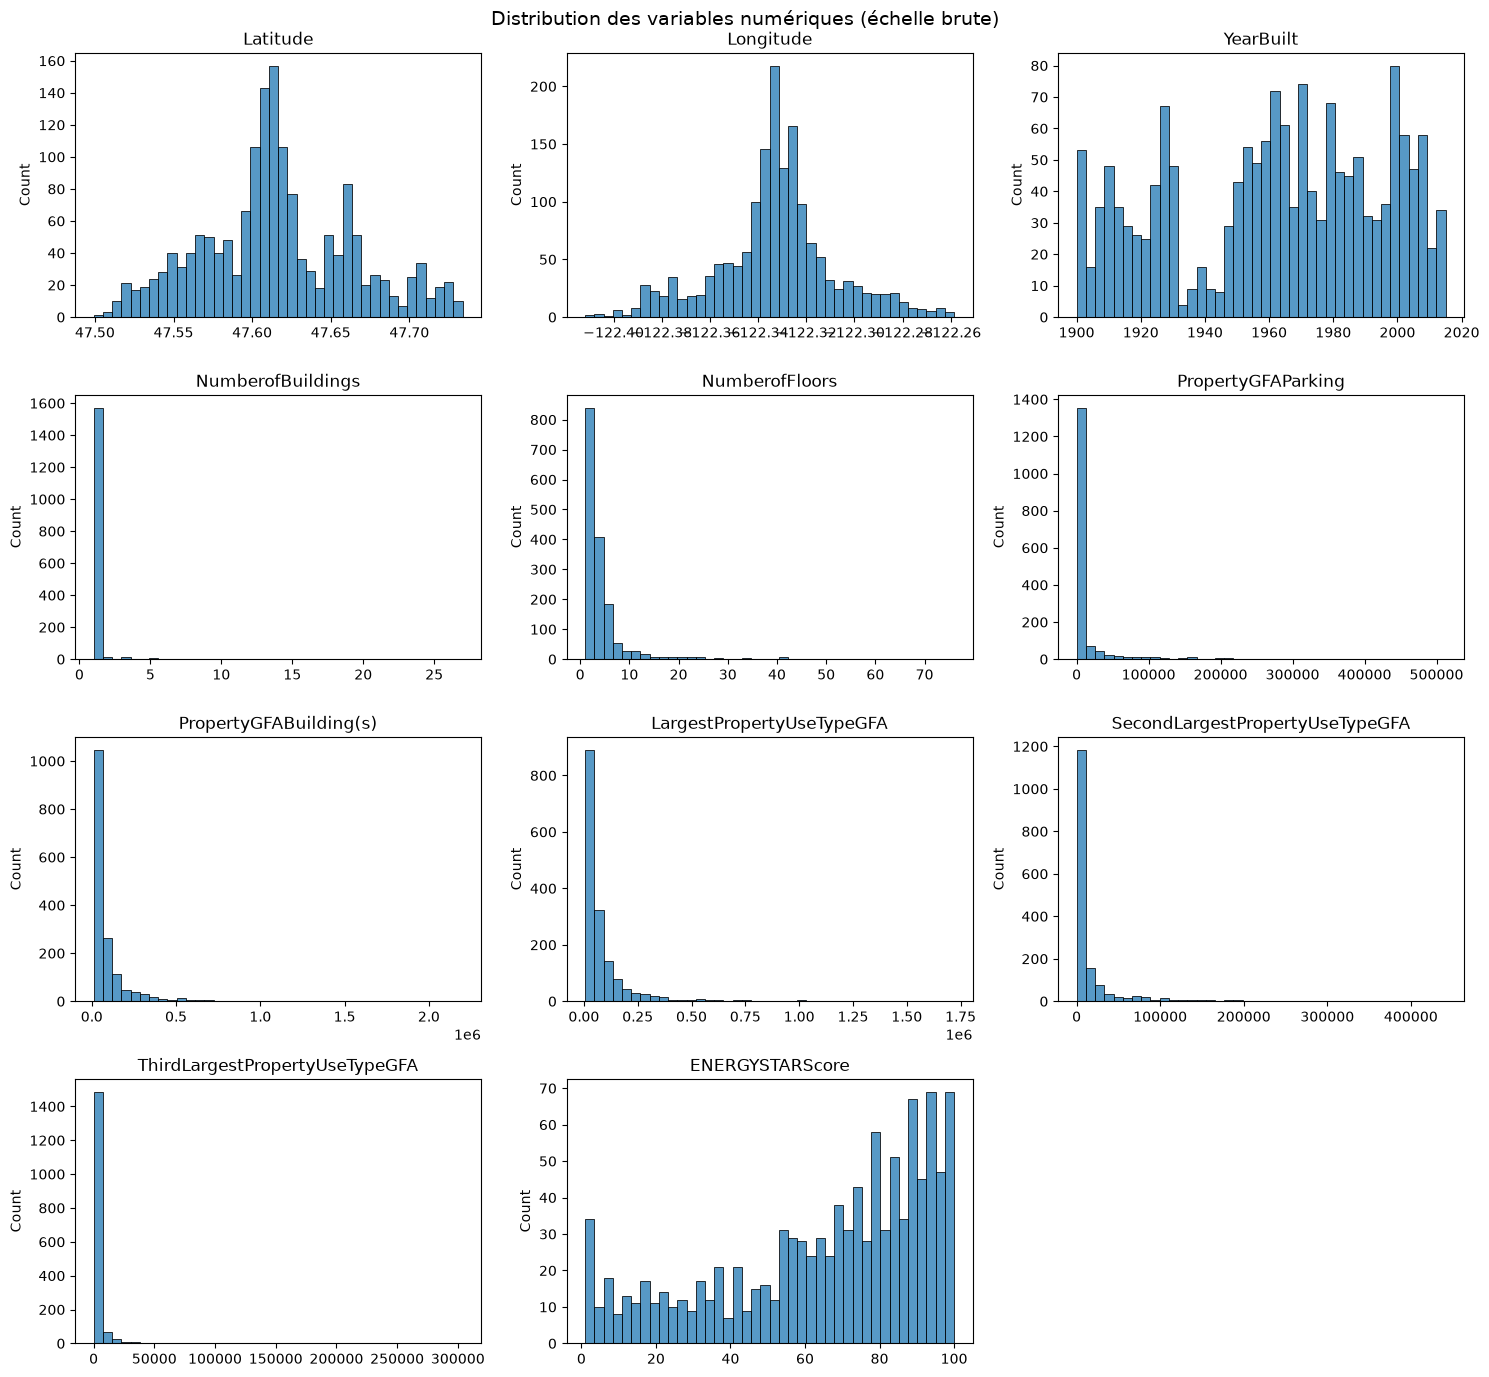

In [38]:
cibles = ["SiteEnergyUse(kBtu)", "TotalGHGEmissions"]
binaires = ["UsesNaturalGas", "UsesSteam"]

# Variables explicatives numériques (hors cibles, déjà étudiées à l'étape 3, et hors binaires)
num_cols = [c for c in df.select_dtypes("number").columns if c not in cibles + binaires]

fig, axes = plt.subplots(4, 3, figsize=(15, 14))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(df[col].dropna(), bins=40, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
for ax in axes.flat[len(num_cols):]:
    ax.set_visible(False)
plt.suptitle("Distribution des variables numériques (échelle brute)", fontsize=14)
plt.tight_layout()
plt.show()

On mesure l'asymétrie de chaque variable avant et après transformation logarithmique.

On utilise `np.log1p(x) = log(1 + x)` plutôt que `np.log(x)` car plusieurs variables contiennent des **0** (pas de parking, pas de 2e usage…) et `log(0)` n'est pas défini. Pour les grandes valeurs, `log1p` et `log` sont quasiment identiques.

In [39]:
asymetrie = pd.DataFrame({
    "skew_brut": df[num_cols].skew(),
    "skew_log1p": np.log1p(df[num_cols].clip(lower=0)).skew(),
    "%_zeros": (df[num_cols] == 0).mean() * 100,
    "min": df[num_cols].min(),
    "médiane": df[num_cols].median(),
    "max": df[num_cols].max(),
}).round(2)
# Longitude est négative : log1p n'a pas de sens, et elle n'est pas asymétrique de toute façon
asymetrie.loc[["Latitude", "Longitude"], "skew_log1p"] = np.nan
asymetrie.sort_values("skew_brut", ascending=False)

,skew_brut,skew_log1p,%_zeros,min,médiane,max
NumberofBuildings,14.64,8.07,0.00,1.00,1.00,27.00
ThirdLargestPropertyUseTypeGFA,11.70,1.59,80.02,0.00,0.00,303910.00
PropertyGFABuilding(s),5.37,1.09,0.00,10925.00,47171.00,2200000.00
LargestPropertyUseTypeGFA,5.25,0.82,0.00,5656.00,43638.00,1719643.00
PropertyGFAParking,5.17,1.54,79.78,0.00,0.00,512608.00
NumberofFloors,5.15,1.38,0.00,1.00,2.00,76.00
SecondLargestPropertyUseTypeGFA,4.71,0.22,52.84,0.00,0.00,441551.00
Latitude,0.23,NaN,0.00,47.50,47.61,47.73
Longitude,-0.06,NaN,0.00,-122.41,-122.33,-122.26
YearBuilt,-0.29,-0.31,0.00,1900.00,1965.50,2015.00


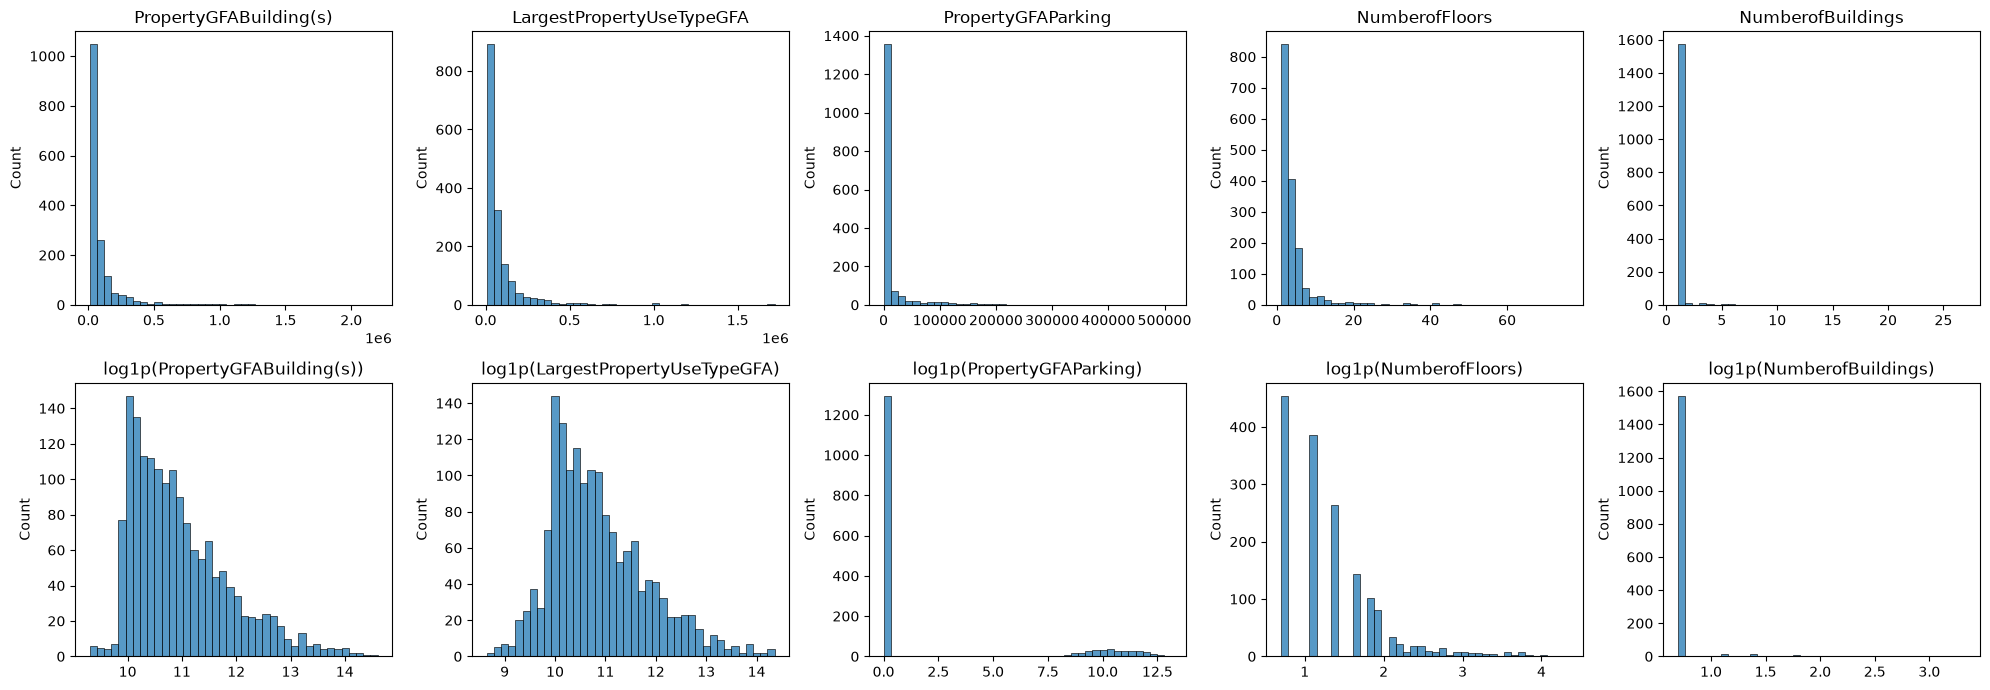

In [40]:
# Variables fortement asymétriques (|skew| > 1) : comparaison brut / log1p
asymetriques = ["PropertyGFABuilding(s)", "LargestPropertyUseTypeGFA", "PropertyGFAParking",
                "NumberofFloors", "NumberofBuildings"]

fig, axes = plt.subplots(2, len(asymetriques), figsize=(20, 7))
for i, col in enumerate(asymetriques):
    sns.histplot(df[col], bins=40, ax=axes[0, i]).set_title(col)
    sns.histplot(np.log1p(df[col]), bins=40, ax=axes[1, i]).set_title(f"log1p({col})")
    axes[0, i].set_xlabel("")
    axes[1, i].set_xlabel("")
plt.tight_layout()
plt.show()

**Observations sur les variables numériques :**

- **Surfaces** (`PropertyGFABuilding(s)`, `LargestPropertyUseTypeGFA`) : très asymétriques (skew ≈ 5), comme les cibles. Après `log1p`, le skew tombe autour de 1, et la distribution devient proche d'une cloche. → **passage au log** pour la modélisation. C'est cohérent avec les cibles en log : la relation surface ↔ consommation, multiplicative, devient linéaire entre les deux logs.
- **`PropertyGFAParking`, `Second/ThirdLargestPropertyUseTypeGFA`** : majoritairement à 0 (80 % des bâtiments sans parking, 53 % sans 2e usage, 80 % sans 3e usage). Le log1p réduit l'asymétrie des valeurs non nulles, mais le pic à 0 reste : c'est une information (absence) et non un défaut. → **log1p**.
- **`NumberofFloors`** : skew de 5 (médiane 2 étages, max 76). → **log1p** (skew 1,4 après).
- **`NumberofBuildings`** : 97 % des propriétés ont 1 seul bâtiment ; le log ne corrige pas cette concentration (skew 8 après). La variable est presque constante et apportera probablement peu d'information.
- **`YearBuilt`** : distribution étalée de 1900 à 2015, peu asymétrique (skew -0,3). → pas de transformation.
- **`Latitude` / `Longitude`** : distributions symétriques. → pas de transformation.
- **`ENERGYSTARScore`** : asymétrique **vers la gauche** (skew -0,8, médiane 73) : beaucoup de bâtiments ont un bon score. Le log aggraverait l'asymétrie (-2,3). → pas de transformation.

### 7.2 Variables binaires

In [41]:
for col in binaires:
    print(f"{col} : {df[col].mean():.1%} des bâtiments")

UsesNaturalGas : 72.3% des bâtiments
UsesSteam : 7.0% des bâtiments


- **72 %** des bâtiments utilisent du gaz naturel : la variable est bien répartie entre les deux modalités.
- **7 %** seulement sont raccordés au réseau de vapeur (essentiellement en centre-ville). Variable déséquilibrée, mais potentiellement importante pour les émissions : la vapeur de Seattle est produite en partie au gaz.

### 7.3 Variables catégorielles

In [42]:
cat_cols = df.select_dtypes(exclude="number").columns.tolist()

resume_cat = pd.DataFrame({
    "nb_modalités": df[cat_cols].nunique(),
    "modalités_<10_bâtiments": [(df[c].value_counts() < 10).sum() for c in cat_cols],
    "modalité_la_plus_fréquente": [df[c].value_counts().index[0] for c in cat_cols],
})
resume_cat

,nb_modalités,modalités_<10_bâtiments,modalité_la_plus_fréquente
BuildingType,5,1,NonResidential
PrimaryPropertyType,21,2,Small- and Mid-Sized Office
Neighborhood,19,6,DOWNTOWN
LargestPropertyUseType,56,35,Office
SecondLargestPropertyUseType,48,36,None
ThirdLargestPropertyUseType,40,30,None


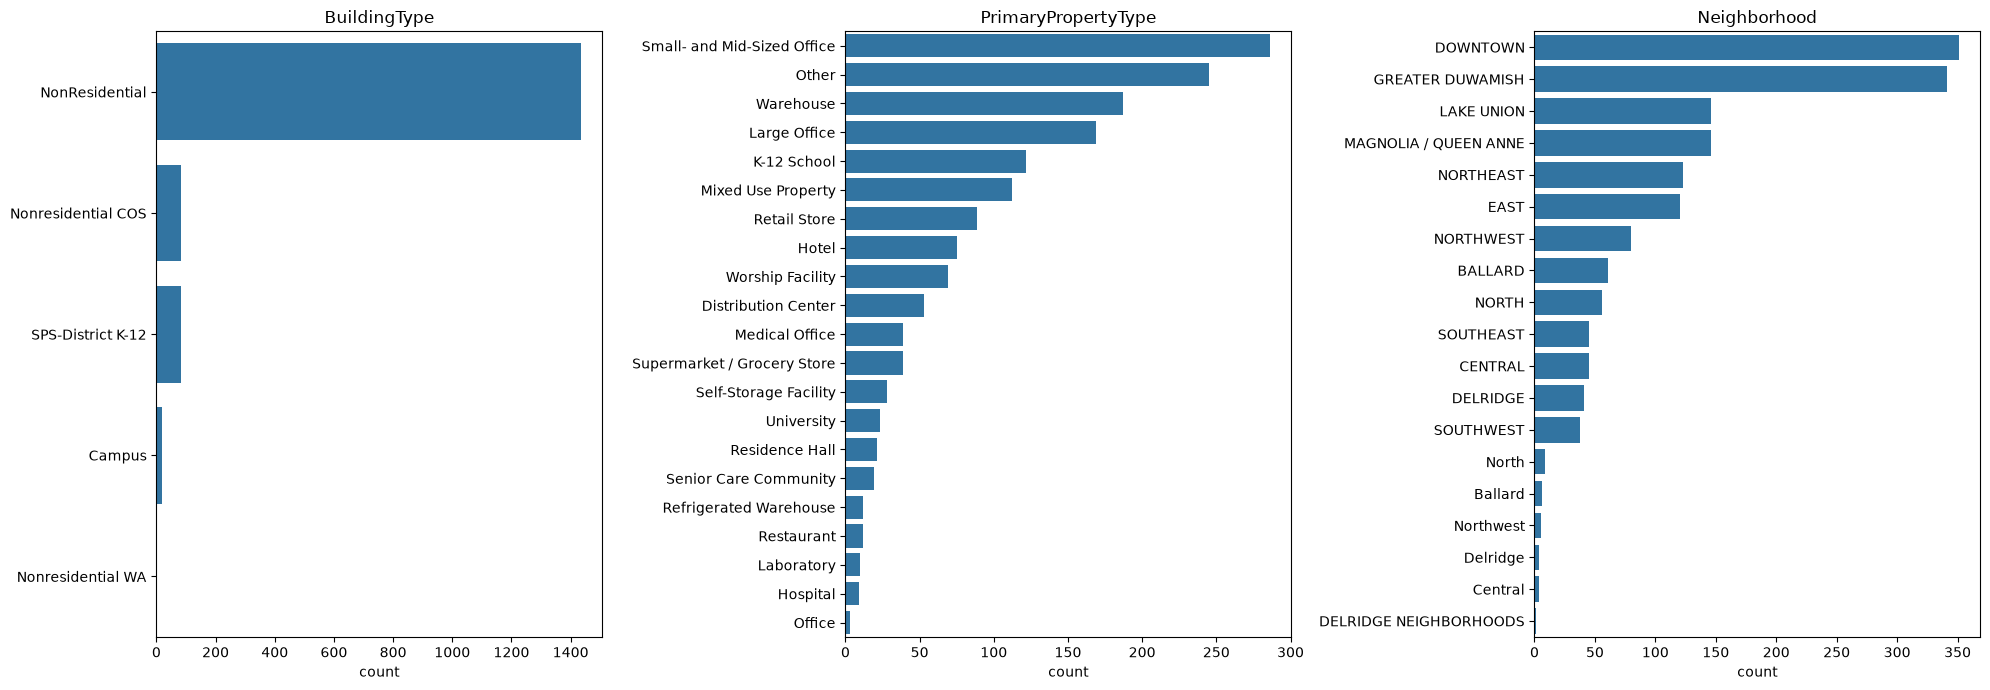

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(20, 7))
for ax, col in zip(axes, ["BuildingType", "PrimaryPropertyType", "Neighborhood"]):
    ordre = df[col].value_counts().index
    sns.countplot(data=df, y=col, order=ordre, ax=ax)
    ax.set_title(col)
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Incohérence de saisie dans `Neighborhood`** : le graphique fait apparaître des doublons qui ne diffèrent que par la casse (`NORTH` / `North`, `BALLARD` / `Ballard`, `DELRIDGE` / `Delridge`…) et une variante `DELRIDGE NEIGHBORHOODS`. Ce sont les mêmes quartiers : on harmonise en majuscules et on fusionne la variante.

In [44]:
# Harmonisation de la casse + fusion de la variante "DELRIDGE NEIGHBORHOODS"
print("Avant :", df["Neighborhood"].nunique(), "quartiers")
df["Neighborhood"] = df["Neighborhood"].str.upper().replace("DELRIDGE NEIGHBORHOODS", "DELRIDGE")
print("Après :", df["Neighborhood"].nunique(), "quartiers")
df["Neighborhood"].value_counts()

Avant : 19 quartiers
Après : 13 quartiers


Neighborhood
DOWNTOWN                 351
GREATER DUWAMISH         341
LAKE UNION               146
MAGNOLIA / QUEEN ANNE    146
NORTHEAST                123
EAST                     120
NORTHWEST                 85
BALLARD                   67
NORTH                     65
CENTRAL                   49
DELRIDGE                  46
SOUTHEAST                 45
SOUTHWEST                 38
Name: count, dtype: int64

In [45]:
# Modalités rares pour BuildingType et PrimaryPropertyType
for col in ["BuildingType", "PrimaryPropertyType"]:
    vc = df[col].value_counts()
    print(f"{col} - modalités < 10 bâtiments :", vc[vc < 10].to_dict())

BuildingType - modalités < 10 bâtiments : {'Nonresidential WA': 1}
PrimaryPropertyType - modalités < 10 bâtiments : {'Hospital': 9, 'Office': 3}


In [46]:
# Les colonnes d'usage ont beaucoup de modalités, dont une majorité très rares
for col in ["LargestPropertyUseType", "SecondLargestPropertyUseType", "ThirdLargestPropertyUseType"]:
    vc = df[col].value_counts()
    print(f"{col} : {len(vc)} modalités, dont {(vc < 10).sum()} avec moins de 10 bâtiments")

LargestPropertyUseType : 56 modalités, dont 35 avec moins de 10 bâtiments
SecondLargestPropertyUseType : 48 modalités, dont 36 avec moins de 10 bâtiments
ThirdLargestPropertyUseType : 40 modalités, dont 30 avec moins de 10 bâtiments


**Observations sur les variables catégorielles :**

- **`BuildingType`** (5 modalités) : très dominée par `NonResidential` (88 %). `Nonresidential WA` ne compte qu'un bâtiment.
- **`PrimaryPropertyType`** (21 modalités) : bien répartie (bureaux, entrepôts, écoles…). Seules 2 modalités ont moins de 10 bâtiments. Cette variable devrait être très informative, la consommation dépendant fortement de l'usage.
- **`Neighborhood`** : après harmonisation, 13 quartiers, tous bien représentés.
- **`Largest/Second/ThirdLargestPropertyUseType`** : **forte cardinalité** (56, 48 et 40 modalités), dont la majorité concerne moins de 10 bâtiments. Un one-hot encoding direct créerait plus de 140 colonnes, presque toutes vides : risque de sur-apprentissage.

**Conséquences pour l'encodage** (étape de preprocessing) :
- regrouper les modalités rares (< 10 bâtiments) dans une catégorie `Other` avant l'encodage ;
- `LargestPropertyUseType` étant en grande partie redondante avec `PrimaryPropertyType`, la question de la garder sera tranchée avec l'analyse bivariée et la réduction de dimensionnalité.

## 8. Analyse bivariée

On étudie maintenant le lien entre chaque variable explicative et les deux cibles. Les cibles sont regardées **en log** (décision de l'étape 3) : sinon, les quelques bâtiments géants écrasent tous les graphiques.

Les variables log sont stockées dans des variables Python à part, **pas dans `df`**, pour ne pas mélanger les transformations avec le jeu de données nettoyé.

In [47]:
E, G = "SiteEnergyUse(kBtu)", "TotalGHGEmissions"
log_E = np.log(df[E])
log_G = np.log(df[G])
log_surface = np.log(df["PropertyGFABuilding(s)"])

# Intensités (rapportées à la surface) : utiles pour comparer des bâtiments de tailles différentes
intensite_E = df[E] / df["PropertyGFABuilding(s)"]            # kBtu / pied²
intensite_G = df[G] / df["PropertyGFABuilding(s)"] * 1000     # kg CO2 / pied²

### 8.1 Surface et cibles

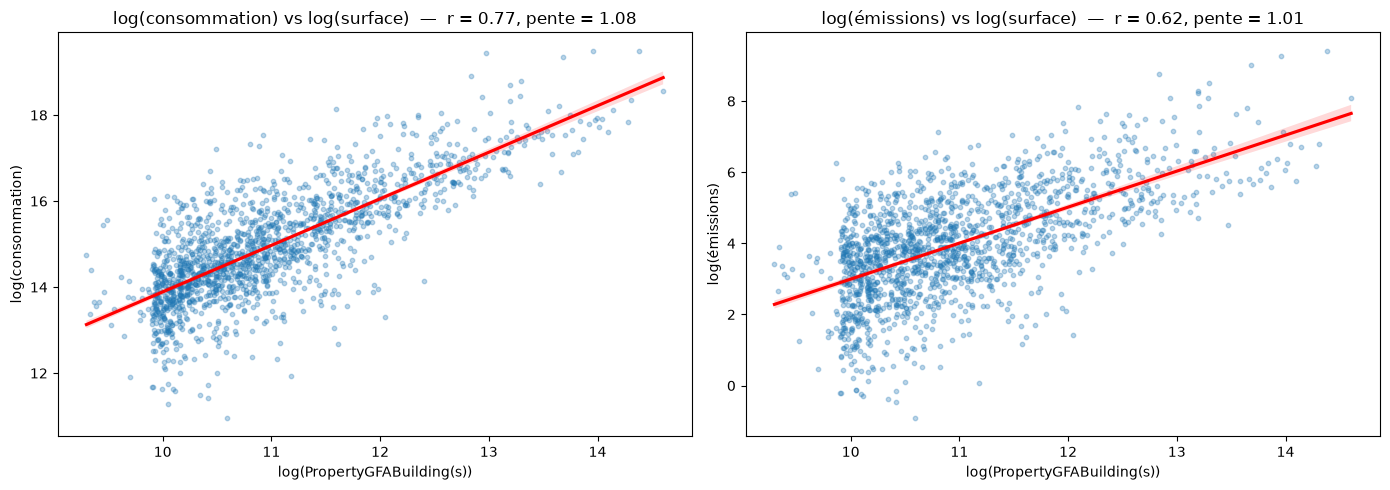

Corrélation en échelle brute (consommation) : 0.68


In [48]:
from scipy import stats

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, y, nom in zip(axes, [log_E, log_G], ["log(consommation)", "log(émissions)"]):
    sns.regplot(x=log_surface, y=y, ax=ax, scatter_kws={"alpha": 0.3, "s": 10}, line_kws={"color": "red"})
    r = stats.pearsonr(log_surface, y)[0]
    pente = np.polyfit(log_surface, y, 1)[0]
    ax.set_title(f"{nom} vs log(surface)  —  r = {r:.2f}, pente = {pente:.2f}")
    ax.set_xlabel("log(PropertyGFABuilding(s))")
    ax.set_ylabel(nom)
plt.tight_layout()
plt.show()

print("Corrélation en échelle brute (consommation) :", round(stats.pearsonr(df["PropertyGFABuilding(s)"], df[E])[0], 2))

**Observations :**
- En log/log, la relation surface ↔ consommation est **nettement linéaire** (r = 0,77). La **pente vaut environ 1** : quand la surface double, la consommation double aussi. La consommation est donc à peu près proportionnelle à la surface, ce qui confirme l'intérêt du passage au log des deux côtés.
- La relation est plus dispersée pour les émissions (r = 0,62) : à surface égale, les émissions dépendent aussi **du type d'énergie utilisée** (voir 8.4).
- La surface est la variable la plus liée aux cibles. La dispersion verticale autour de la droite (un facteur 10 entre deux bâtiments de même surface) est ce que les autres variables (type, énergie, score) devront expliquer.

### 8.2 Autres variables numériques

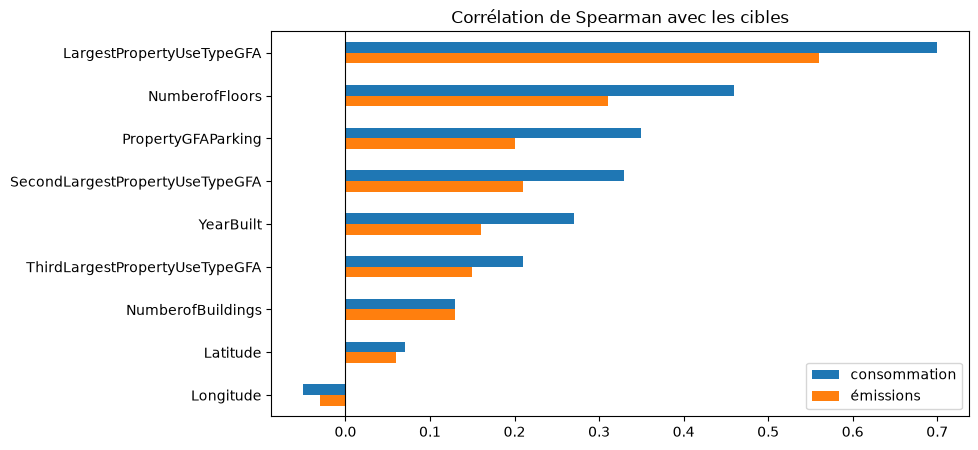

,consommation,émissions
LargestPropertyUseTypeGFA,0.70,0.56
NumberofFloors,0.46,0.31
PropertyGFAParking,0.35,0.20
SecondLargestPropertyUseTypeGFA,0.33,0.21
YearBuilt,0.27,0.16
ThirdLargestPropertyUseTypeGFA,0.21,0.15
NumberofBuildings,0.13,0.13
Latitude,0.07,0.06
Longitude,-0.05,-0.03


In [49]:
# Corrélation de Spearman (basée sur les rangs) : robuste aux valeurs extrêmes
# et capable de détecter des relations monotones non linéaires
autres_num = ["LargestPropertyUseTypeGFA", "SecondLargestPropertyUseTypeGFA", "ThirdLargestPropertyUseTypeGFA",
              "PropertyGFAParking", "NumberofFloors", "NumberofBuildings", "YearBuilt",
              "Latitude", "Longitude"]
correl = pd.DataFrame({
    "consommation": [stats.spearmanr(df[c], log_E)[0] for c in autres_num],
    "émissions": [stats.spearmanr(df[c], log_G)[0] for c in autres_num],
}, index=autres_num).round(2).sort_values("consommation", ascending=False)

correl.plot.barh(figsize=(9, 5), title="Corrélation de Spearman avec les cibles")
plt.axvline(0, color="black", linewidth=0.8)
plt.gca().invert_yaxis()
plt.show()
correl

**Observations :**
- `LargestPropertyUseTypeGFA` (ρ = 0,70) est presque aussi corrélée que la surface bâtie : c'est logique, pour la plupart des bâtiments l'usage principal occupe l'essentiel de la surface. Les deux variables sont donc **redondantes** (à vérifier dans la matrice de corrélation).
- `NumberofFloors` (0,46), les surfaces de parking et de 2e usage (≈ 0,35) sont liées aux cibles, mais en partie parce qu'elles **grandissent avec la taille du bâtiment**.
- `YearBuilt` : lien faible (0,27). Les bâtiments récents sont en moyenne plus grands.
- `Latitude`, `Longitude` : aucun lien direct (|ρ| < 0,1). La localisation n'agit pas de façon linéaire : un éventuel effet passera plutôt par le quartier.

### 8.3 Type de bâtiment et quartier

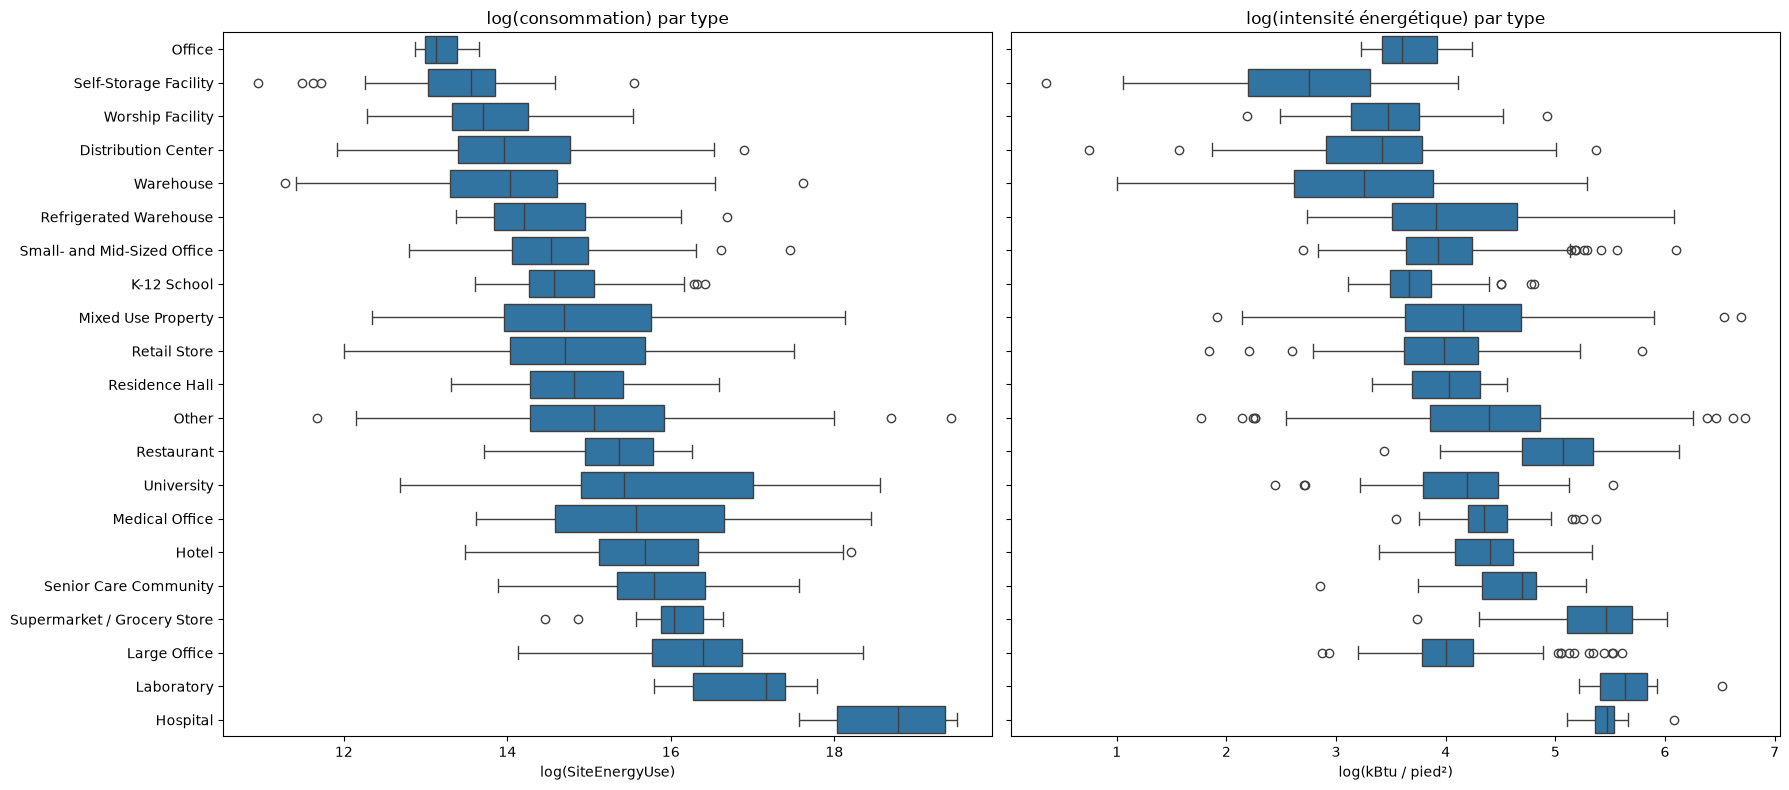

PrimaryPropertyType
Self-Storage Facility           16.0
Warehouse                       26.0
Distribution Center             31.0
Worship Facility                32.0
Office                          37.0
K-12 School                     39.0
Refrigerated Warehouse          50.0
Small- and Mid-Sized Office     51.0
Retail Store                    54.0
Large Office                    55.0
Residence Hall                  56.0
Mixed Use Property              64.0
University                      66.0
Medical Office                  77.0
Other                           81.0
Hotel                           82.0
Senior Care Community          110.0
Restaurant                     159.0
Supermarket / Grocery Store    235.0
Hospital                       239.0
Laboratory                     280.0
dtype: float64

In [50]:
ordre_type = log_E.groupby(df["PrimaryPropertyType"]).median().sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(18, 8), sharey=True)
sns.boxplot(x=log_E, y=df["PrimaryPropertyType"], order=ordre_type, ax=axes[0])
axes[0].set_title("log(consommation) par type")
axes[0].set_xlabel("log(SiteEnergyUse)")
sns.boxplot(x=np.log(intensite_E), y=df["PrimaryPropertyType"], order=ordre_type, ax=axes[1])
axes[1].set_title("log(intensité énergétique) par type")
axes[1].set_xlabel("log(kBtu / pied²)")
axes[0].set_ylabel("")
plt.tight_layout()
plt.show()

intensite_E.groupby(df["PrimaryPropertyType"]).median().sort_values().round(0)

**Observations :**
- Le type de bâtiment change **énormément** la consommation : à surface égale (graphique de droite), un laboratoire ou un hôpital consomme environ **18 fois plus** au pied² qu'un garde-meubles (≈ 280 contre 16 kBtu/pied²).
- Les types se regroupent logiquement : stockage peu chauffé (garde-meubles, entrepôts) en bas ; activités intensives en énergie (supermarchés avec froid alimentaire, hôpitaux ouverts 24h/24, laboratoires) en haut.
- `PrimaryPropertyType` est donc probablement la **2e variable la plus importante** après la surface : c'est elle qui explique la dispersion observée en 8.1.

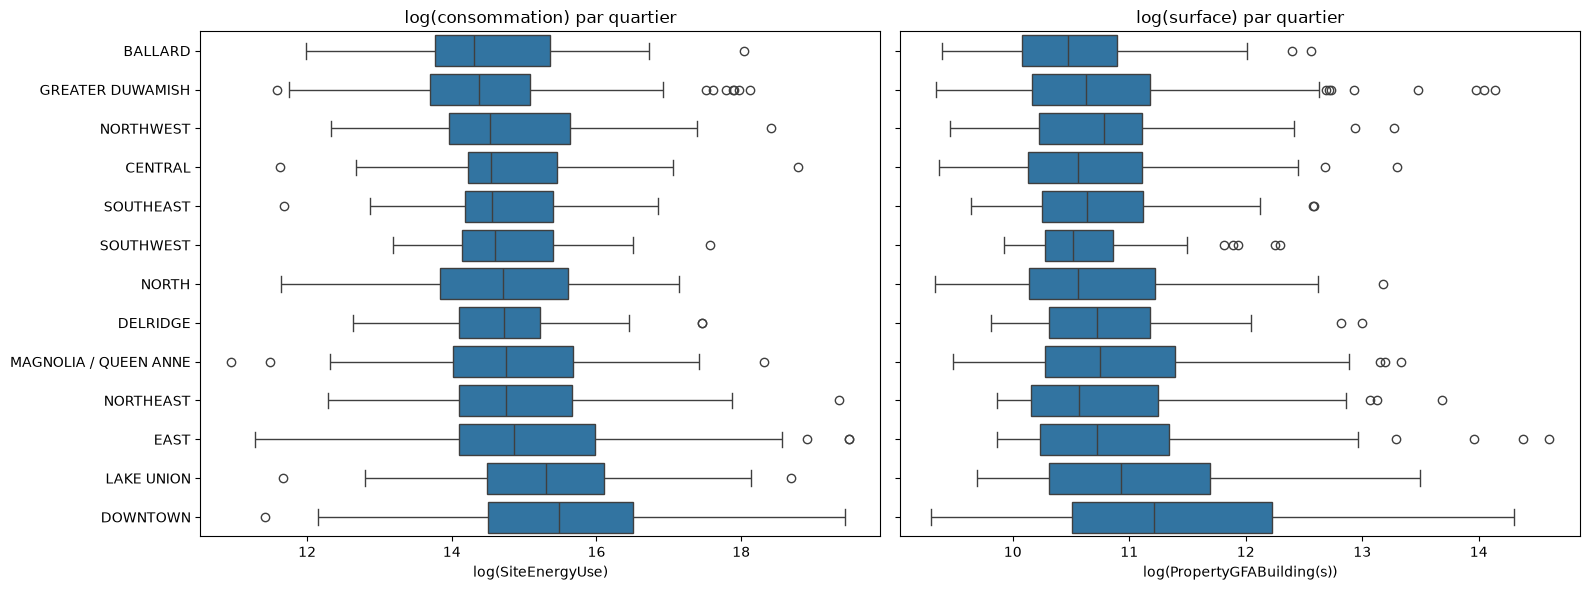

In [51]:
ordre_quartier = log_E.groupby(df["Neighborhood"]).median().sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
sns.boxplot(x=log_E, y=df["Neighborhood"], order=ordre_quartier, ax=axes[0])
axes[0].set_title("log(consommation) par quartier")
axes[0].set_xlabel("log(SiteEnergyUse)")
sns.boxplot(x=log_surface, y=df["Neighborhood"], order=ordre_quartier, ax=axes[1])
axes[1].set_title("log(surface) par quartier")
axes[1].set_xlabel("log(PropertyGFABuilding(s))")
axes[0].set_ylabel("")
plt.tight_layout()
plt.show()

**Observations :**
- `DOWNTOWN` et `LAKE UNION` consomment nettement plus que les autres quartiers.
- Mais le graphique de droite montre que ce sont aussi les quartiers où **les bâtiments sont les plus grands** (tours de bureaux du centre-ville). L'effet du quartier passe donc en grande partie **par la taille**, pas par la localisation elle-même : c'est une **variable de confusion**. Le quartier devrait apporter peu d'information une fois la surface connue.

### 8.4 Gaz, vapeur et émissions

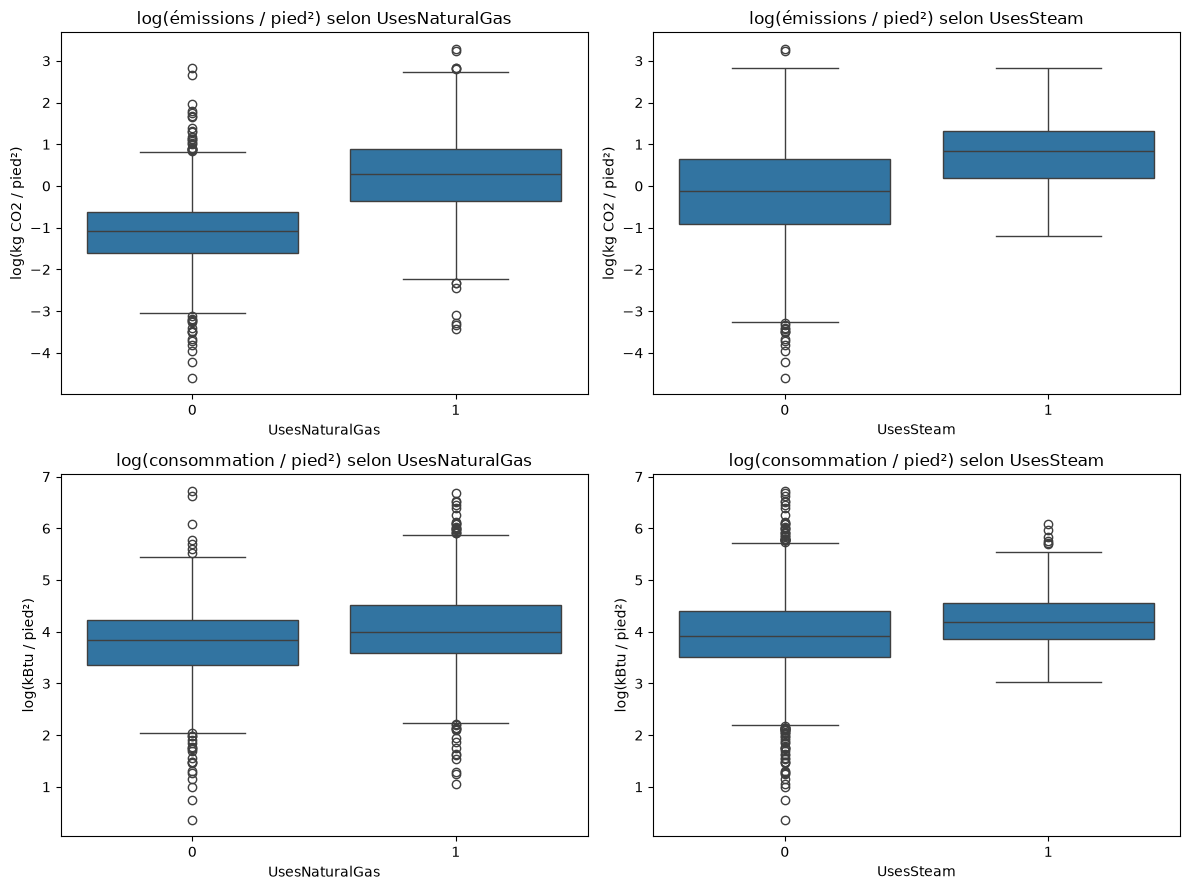

,UsesNaturalGas,UsesSteam
émissions médianes (kg CO2/pied²) - non,0.34,0.88
émissions médianes (kg CO2/pied²) - oui,1.32,2.32
consommation médiane (kBtu/pied²) - non,46.65,50.72
consommation médiane (kBtu/pied²) - oui,54.45,65.97


In [51]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for j, col in enumerate(binaires):
    sns.boxplot(x=df[col], y=np.log(intensite_G), ax=axes[0, j])
    axes[0, j].set_title(f"log(émissions / pied²) selon {col}")
    axes[0, j].set_ylabel("log(kg CO2 / pied²)")
    sns.boxplot(x=df[col], y=np.log(intensite_E), ax=axes[1, j])
    axes[1, j].set_title(f"log(consommation / pied²) selon {col}")
    axes[1, j].set_ylabel("log(kBtu / pied²)")
plt.tight_layout()
plt.show()

pd.DataFrame({
    col: {
        "émissions médianes (kg CO2/pied²) - non": intensite_G[df[col] == 0].median(),
        "émissions médianes (kg CO2/pied²) - oui": intensite_G[df[col] == 1].median(),
        "consommation médiane (kBtu/pied²) - non": intensite_E[df[col] == 0].median(),
        "consommation médiane (kBtu/pied²) - oui": intensite_E[df[col] == 1].median(),
    } for col in binaires
}).round(2)

**Observations : c'est le résultat le plus marquant de l'analyse bivariée.**
- À surface égale, les bâtiments **au gaz émettent environ 4 fois plus** de CO2 (1,32 contre 0,34 kg/pied²), alors qu'ils **ne consomment presque pas plus** d'énergie (54 contre 47 kBtu/pied²).
- Explication : l'électricité de Seattle est produite essentiellement par des **barrages hydroélectriques**, qui n'émettent quasiment pas de CO2, alors que le gaz brûlé sur place en émet beaucoup.
- Même constat pour la vapeur (environ 2,6 fois plus d'émissions), produite en partie à partir de gaz.
- Conséquence : **les deux cibles ne s'expliquent pas par les mêmes variables**. La consommation dépend surtout de la taille et de l'usage ; les émissions dépendent en plus fortement de la **source d'énergie**. `UsesNaturalGas` et `UsesSteam` seront probablement des variables clés pour prédire les émissions.

### 8.5 ENERGY STAR Score et émissions

1073 bâtiments avec un score


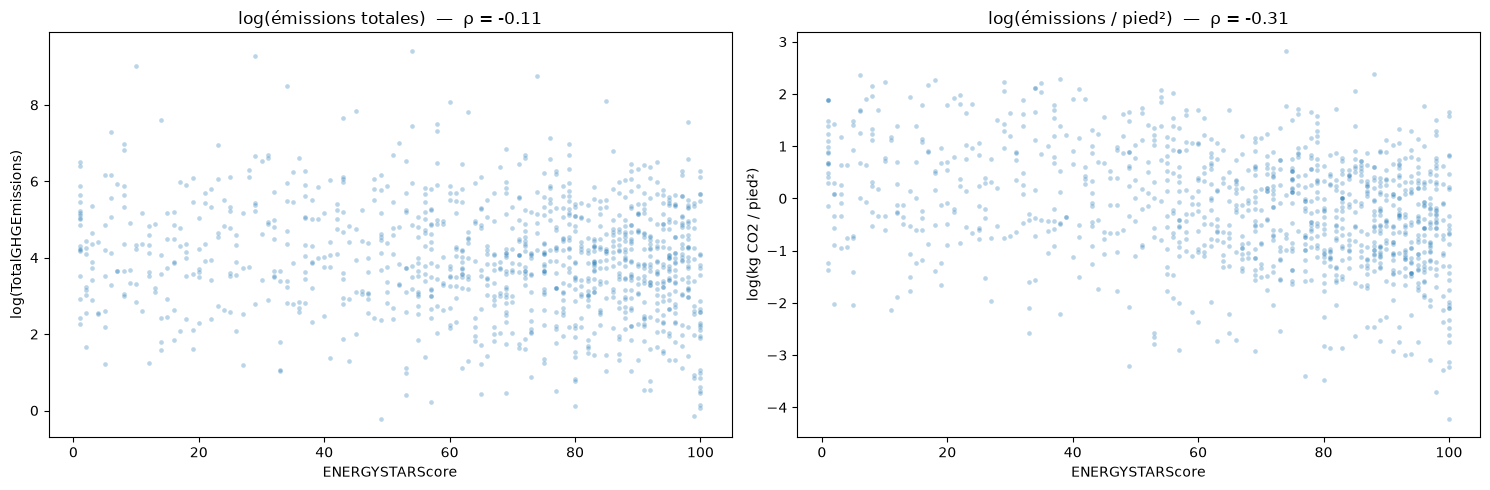

ENERGYSTARScore
Q1 (score bas)     1.34
Q2                 0.91
Q3                 0.77
Q4 (score haut)    0.57
Name: kg CO2 / pied² (médiane), dtype: float64

In [52]:
avec_score = df["ENERGYSTARScore"].notna()
score = df.loc[avec_score, "ENERGYSTARScore"]
print(f"{avec_score.sum()} bâtiments avec un score")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Émissions totales : dominées par la taille du bâtiment
sns.scatterplot(x=score, y=log_G[avec_score], alpha=0.3, s=12, ax=axes[0])
axes[0].set_title(f"log(émissions totales)  —  ρ = {stats.spearmanr(score, log_G[avec_score])[0]:.2f}")
axes[0].set_ylabel("log(TotalGHGEmissions)")

# Émissions par pied² : on neutralise l'effet taille
sns.scatterplot(x=score, y=np.log(intensite_G[avec_score]), alpha=0.3, s=12, ax=axes[1])
axes[1].set_title(f"log(émissions / pied²)  —  ρ = {stats.spearmanr(score, intensite_G[avec_score])[0]:.2f}")
axes[1].set_ylabel("log(kg CO2 / pied²)")
plt.tight_layout()
plt.show()

# Émissions par pied² selon le quartile de score
quartile_score = pd.qcut(score, 4, labels=["Q1 (score bas)", "Q2", "Q3", "Q4 (score haut)"])
intensite_G[avec_score].groupby(quartile_score, observed=True).median().round(2).rename("kg CO2 / pied² (médiane)")

**Observations :**
- Avec les **émissions totales**, le lien est très faible (ρ = -0,11) : un grand bâtiment efficace émet quand même plus qu'un petit bâtiment inefficace. La taille masque l'effet du score.
- Dès qu'on **rapporte les émissions à la surface**, le lien apparaît nettement (ρ = -0,31) : les bâtiments du quart le mieux noté émettent environ **2,3 fois moins** au pied² que ceux du quart le moins bien noté (0,57 contre 1,34 kg/pied²).
- Le score apporte donc une information **complémentaire à la surface** : l'efficacité énergétique du bâtiment, qu'aucune autre variable ne mesure directement. C'est un premier signe de son intérêt pour la prédiction ; la modélisation permettra de quantifier ce gain (modèle avec / sans score, cf. étape 4).

### Synthèse de l'analyse bivariée

| Variable | Lien avec les cibles | Commentaire |
|---|---|---|
| Surface bâtie (log) | **très fort** | relation linéaire en log/log, pente ≈ 1 |
| `PrimaryPropertyType` | **très fort** | intensité multipliée par 18 entre types extrêmes |
| `UsesNaturalGas`, `UsesSteam` | **fort sur les émissions** | quasi nul sur la consommation |
| `ENERGYSTARScore` | modéré, **à surface égale** | information complémentaire (efficacité) |
| `LargestPropertyUseTypeGFA` | fort | mais redondante avec la surface bâtie |
| `NumberofFloors`, parking, 2e usage | modéré | en partie un effet de taille |
| `Neighborhood` | faible | effet passant surtout par la taille (confusion) |
| `YearBuilt`, `Latitude`, `Longitude` | faible à nul | |

Prochaine étape : la **matrice de corrélation** et les **tests statistiques** pour confirmer ces observations et repérer les variables redondantes.